# 03 -- E-MILES templates: a real, dense stellar-population library

**Goal:** `kinextract.emiles` is a first-class template source alongside
the real 33-star MUSE library used elsewhere in this package -- a full
E-MILES (Vazdekis et al. 2016) single stellar population (SSP) grid, packed
once from the raw FITS release into a single portable `.npz` file, with
**wavelength-dependent LSF matching done at pack time** (this package's own
design choice -- see Section 3), not at fit time with a single scalar FWHM
the way a simpler pipeline might do it.

This notebook covers the whole API:
1. What's shipped (`src/kinextract/template_data/emiles_muse_grid.npz`)
   and how it was built.
2. Visualizing template diversity across age and metallicity.
3. Why LSF matching happens at pack time, and what "cannot-sharpen"
   pixels mean.
4. Building your *own* grid from a raw E-MILES download
   (`pack_emiles_templates`) -- demonstrated on a small synthetic stand-in
   so this notebook needs no external data, alongside the exact real
   invocation used to build the shipped grid.
5. Selecting a template subset for a fit (`load_emiles_templates`).
6. Plugging the result into `build_template_stack` for an actual LOSVD fit.

See `02_realistic_mock_fit.ipynb` for a full fit built on a subset of this
same grid, and `04_template_calibration.ipynb` for using the *full*
636-template grid as a mismatch/selection diagnostic on real data.


## 1. What's shipped

The shipped grid is E-MILES BaSTI-isochrone, `baseFe` (base-alpha,
solar-scaled) SSPs, IMF bi1.30 (bimodal, slope 1.30 -- the Milky-Way-like
default), trimmed to the 3000-10500 Angstrom range and LSF-matched to
MUSE's wavelength-dependent resolution. **Only this one IMF is shipped** --
`pack_emiles_templates` can build a grid for any other IMF type/slope in
the raw E-MILES release (see Section 4), but repacking needs the ~1.4GB raw
download.

In [1]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt

from kinextract import (
    load_emiles_templates, parse_emiles_filename, pack_emiles_templates,
    build_template_stack, FitConfig, muse_lsf_fwhm,
)

EMILES_GRID = "../../src/kinextract/template_data/emiles_muse_grid.npz"

raw = np.load(EMILES_GRID, allow_pickle=True)
print(f"provenance : {raw['source']}")
print(f"wavelength : {raw['wavelength'].min():.1f}-{raw['wavelength'].max():.1f} Angstrom, "
      f"{len(raw['wavelength'])} pixels")
print(f"grid       : {raw['flux'].shape[1]} templates "
      f"({len(set(raw['ages'].tolist()))} ages x {len(set(raw['metals'].tolist()))} metallicities)")
print(f"IMF        : bi{sorted(set(raw['imf_slope'].tolist()))[0]:.2f}")
print(f"ages (Gyr) : {sorted(set(raw['ages'].tolist()))}")
print(f"[M/H]      : {sorted(set(raw['metals'].tolist()))}")


provenance : E-MILES BaSTI/baseFe, IMF bi1.30, 636 templates (53 ages x 12 metallicities), packed by kinextract.emiles.pack_emiles_templates, LSF-matched to MUSE (wavelength-dependent) (cannot-sharpen fraction 0.285).
wavelength : 3000.5-10499.3 Angstrom, 8333 pixels
grid       : 636 templates (53 ages x 12 metallicities)
IMF        : bi1.30
ages (Gyr) : [0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 2.75, 3.0, 3.25, 3.5, 3.75, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0, 10.5, 11.0, 11.5, 12.0, 12.5, 13.0, 13.5, 14.0]
[M/H]      : [-2.27, -1.79, -1.49, -1.26, -0.96, -0.66, -0.35, -0.25, 0.06, 0.15, 0.26, 0.4]


## 2. Visualizing template diversity across age and metallicity

Two physically expected trends, shown directly rather than assumed: at
fixed metallicity, older populations should show deeper/broader Balmer
lines relaxing and CaII triplet strengthening; at fixed age, higher
metallicity should deepen metal absorption features.

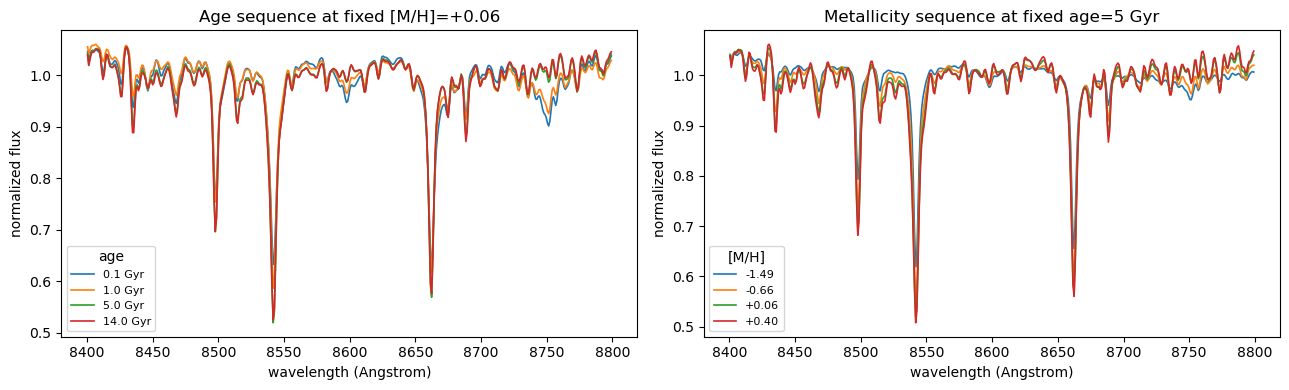

In [2]:
WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0  # CaII triplet, this package's default MUSE fit window

ages_to_show = [0.1, 1.0, 5.0, 14.0]
templates_age, _, names_age, _, _ = load_emiles_templates(
    EMILES_GRID, select=[(a, 0.06) for a in ages_to_show],
)
wavelength = np.load(EMILES_GRID, allow_pickle=True)["wavelength"]
mask = (wavelength >= WAVEFITMIN) & (wavelength <= WAVEFITMAX)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
for age, t in zip(ages_to_show, templates_age):
    ax.plot(wavelength[mask], t[mask] / np.median(t[mask]), lw=1.2, label=f'{age:.1f} Gyr')
ax.set_xlabel('wavelength (Angstrom)'); ax.set_ylabel('normalized flux')
ax.set_title('Age sequence at fixed [M/H]=+0.06'); ax.legend(fontsize=8, title='age')

metals_to_show = [-1.49, -0.66, 0.06, 0.40]
templates_z, _, names_z, _, _ = load_emiles_templates(
    EMILES_GRID, select=[(5.0, z) for z in metals_to_show],
)
ax = axes[1]
for z, t in zip(metals_to_show, templates_z):
    ax.plot(wavelength[mask], t[mask] / np.median(t[mask]), lw=1.2, label=f'{z:+.2f}')
ax.set_xlabel('wavelength (Angstrom)'); ax.set_ylabel('normalized flux')
ax.set_title('Metallicity sequence at fixed age=5 Gyr'); ax.legend(fontsize=8, title='[M/H]')
plt.tight_layout(); plt.show()


## 3. LSF matching, done at pack time

Every SSP template starts at E-MILES' own native resolution (a fixed
FWHM in the optical, per the release notes), which does not match MUSE's
own wavelength-*dependent* instrumental resolution. Before a template can
be used to model a MUSE spectrum, its resolution must be degraded to
match MUSE's -- **and MUSE's resolution changes with wavelength**, so a
single scalar FWHM correction (a common, simpler approach, applied at fit
time) is only ever exactly right at one wavelength.

`pack_emiles_templates` instead calls `match_gaussian_lsf` **once, at pack
time**, using the actual wavelength-dependent target curve (`muse_lsf_fwhm`
below) -- so every template in the shipped grid is already correctly,
locally LSF-matched before it ever reaches a fit, and the (small, one-time)
convolution cost is paid once per template rather than once per fit.

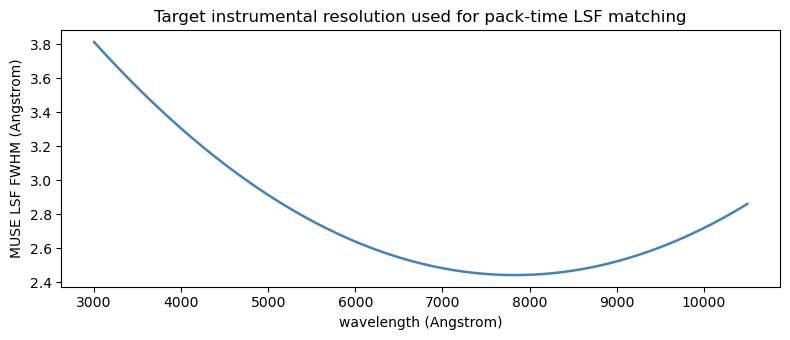

cannot-sharpen fraction (from the shipped grid's own provenance string):
  E-MILES BaSTI/baseFe, IMF bi1.30, 636 templates (53 ages x 12 metallicities), packed by kinextract.emiles.pack_emiles_templates, LSF-matched to MUSE (wavelength-dependent) (cannot-sharpen fraction 0.285).

This means ~28.5% of the packed wavelength range has E-MILES' own native FWHM
already broader than MUSE's target FWHM there -- those pixels are passed through
unconvolved (a template cannot be sharpened by more convolution) rather than silently
mismatched. See `match_gaussian_lsf`'s own docstring for the mechanism.


In [3]:
wave_plot = np.linspace(3000, 10500, 500)
plt.figure(figsize=(8, 3.5))
plt.plot(wave_plot, muse_lsf_fwhm(wave_plot), lw=1.8, color='steelblue')
plt.xlabel('wavelength (Angstrom)'); plt.ylabel('MUSE LSF FWHM (Angstrom)')
plt.title('Target instrumental resolution used for pack-time LSF matching')
plt.tight_layout(); plt.show()

print("cannot-sharpen fraction (from the shipped grid's own provenance string):")
print(f"  {raw['source']}")
print()
print("This means ~28.5% of the packed wavelength range has E-MILES' own native FWHM")
print("already broader than MUSE's target FWHM there -- those pixels are passed through")
print("unconvolved (a template cannot be sharpened by more convolution) rather than silently")
print("mismatched. See `match_gaussian_lsf`'s own docstring for the mechanism.")


## 4. Building your own grid (`pack_emiles_templates`)

The shipped grid was built from the real, raw E-MILES BaSTI/baseFe release
(`EMILES_BASTI_BASE_BI_FITS.tar.gz`, ~1.4GB) with:

```python
pack_emiles_templates(
    "/path/to/EMILES_BASTI_BASE_BI_FITS.tar.gz",
    "emiles_muse_grid.npz",
    imf_slope="1.30", imf_type="bi",
    target_lsf_fwhm=muse_lsf_fwhm, template_fwhm=2.51,
    wave_range=(3000.0, 10500.0),
)
```

(took 8.4 seconds for all 636 templates -- not shown here since it needs
the real ~1.4GB download). The cell below demonstrates the exact same API
end-to-end on a small, synthetic, MILES-convention FITS set instead, so
this notebook needs no external data -- the same pattern `tests/
test_emiles.py` uses for its own fixtures.

In [4]:
import tempfile, os
from astropy.io import fits


def _write_fake_emiles_fits(directory, imf_type="bi", imf_slope=1.30, metal=0.06, age=1.0,
                             wave_min=8000.0, cdelt=0.9, n_pix=1200):
    sign = "m" if metal < 0 else "p"
    name = f"E{imf_type}{imf_slope:.2f}Z{sign}{abs(metal):.2f}T{age:09.4f}_iTp0.00_baseFe.fits"
    wave = wave_min + np.arange(n_pix) * cdelt
    flux = 1.0 - 0.3 * np.exp(-0.5 * ((wave - (wave_min + wave[-1]) / 2) / 50.0) ** 2)
    hdu = fits.PrimaryHDU(flux.astype(np.float32))
    hdu.header["CRVAL1"] = wave_min
    hdu.header["CDELT1"] = cdelt
    hdu.writeto(os.path.join(directory, name), overwrite=True)
    return name


with tempfile.TemporaryDirectory() as tmpdir:
    for metal in (-0.66, 0.06, 0.40):
        for age in (1.0, 5.0, 14.0):
            _write_fake_emiles_fits(tmpdir, metal=metal, age=age)

    out_path = os.path.join(tmpdir, "demo_grid.npz")
    pack_emiles_templates(tmpdir, out_path, target_lsf_fwhm=muse_lsf_fwhm, template_fwhm=2.51, verbose=True)

    demo_templates, demo_wave, demo_names, demo_ages, demo_metals = load_emiles_templates(out_path)
    print(f"\nloaded back {len(demo_templates)} templates from the freshly-packed demo grid")


wrote 9 templates to /var/folders/zp/_mj2qgk5107f3gf_2gnw4gnm0000gs/T/tmppae2lk40/demo_grid.npz
cannot-sharpen fraction: 0.8333

loaded back 9 templates from the freshly-packed demo grid


## 5. Selecting a template subset for a fit

`load_emiles_templates(select=...)` filters to specific (age, metallicity)
pairs, matched with a small floating-point tolerance -- and raises a clear
`ValueError` listing every available pair if you ask for one that isn't
there (not a silent nearest-neighbor fallback, which could quietly hand
you a very different population than intended).

In [5]:
try:
    load_emiles_templates(EMILES_GRID, select=[(1.0, 0.06), (99.0, 99.0)])
except ValueError as e:
    msg = str(e)
    print(msg[:300] + (" ... [truncated]" if len(msg) > 300 else ""))


load_emiles_templates: no packed template matches (age=99.0, metal=99.0) within atol=0.001 -- available (age, metal) pairs: [(0.03, -2.27), (0.03, -1.79), (0.03, -1.49), (0.03, -1.26), (0.03, -0.96), (0.03, -0.66), (0.03, -0.35), (0.03, -0.25), (0.03, 0.06), (0.03, 0.15), (0.03, 0.26), (0.03, 0.4),  ... [truncated]


## 6. Plugging into `build_template_stack` for an actual fit

In [6]:
from kinextract import gauss_hermite_model, compute_losvd_moments
from kinextract.multi_template import fit_losvd

templates, template_wave, names, ages, metals = load_emiles_templates(
    EMILES_GRID, select=[(1.0, 0.06), (5.0, 0.06), (14.0, 0.06), (14.0, -0.66), (14.0, 0.40)],
)
# wave_fit is a MUSE-pixel-sampling (1.25 Angstrom/pix) observed grid, distinct from
# template_wave (E-MILES' own, finer ~0.9 Angstrom/pix native grid) -- build_template_stack
# interpolates the templates onto wave_fit, matching this package's real-data convention.
observed_wavelength = 4750.0 + np.arange(3681) * 1.25
wave_fit = observed_wavelength[(observed_wavelength >= WAVEFITMIN) & (observed_wavelength <= WAVEFITMAX)]

TRUE_V, TRUE_SIGMA = -20.0, 120.0
cfg = FitConfig(vmin=TRUE_V - 7 * TRUE_SIGMA, vmax=TRUE_V + 7 * TRUE_SIGMA)
v_grid = cfg.build_velocity_grid()
b_truth = np.maximum(gauss_hermite_model(v_grid, 1.0, TRUE_V, TRUE_SIGMA, 0.0, 0.0), 0.0)
b_truth /= b_truth.sum()

A_stack = build_template_stack(wave_fit, template_wave, templates, v_grid)
rng = np.random.default_rng(0)
true_w = rng.dirichlet(np.ones(len(templates)))
galaxy_noiseless = sum(true_w[k] * (A_stack[k] @ b_truth) for k in range(len(templates)))
noise_level = np.median(galaxy_noiseless) / 80.0
galaxy = galaxy_noiseless + rng.normal(0.0, noise_level, len(wave_fit))
errors = np.full(len(wave_fit), noise_level)
A_stack_w = A_stack / errors[None, :, None]
y_w = galaxy / errors

result = fit_losvd(A_stack_w, y_w, cfg)
moments = compute_losvd_moments(v_grid, result['b'], fit_h3h4=True)
print(f"true sigma={TRUE_SIGMA:.0f}, recovered sigma={moments['sherm']:.1f}  "
      f"true V={TRUE_V:.0f}, recovered V={moments['vherm']:+.1f}  success={result['success']}")

w_norm = result['w'] / result['w'].sum()
print(f"\n{'template':>45}  {'true w':>8}  {'recovered w':>12}")
for k, n in enumerate(names):
    print(f"{n:>45}  {true_w[k]:>8.3f}  {w_norm[k]:>12.3f}")


true sigma=120, recovered sigma=118.6  true V=-20, recovered V=-17.7  success=True

                                     template    true w   recovered w
    Ebi1.30Zp0.06T01.0000_iTp0.00_baseFe.fits     0.299         0.384
    Ebi1.30Zp0.06T05.0000_iTp0.00_baseFe.fits     0.449         0.000
    Ebi1.30Zp0.06T14.0000_iTp0.00_baseFe.fits     0.009         0.000
    Ebi1.30Zm0.66T14.0000_iTp0.00_baseFe.fits     0.001         0.120
    Ebi1.30Zp0.40T14.0000_iTp0.00_baseFe.fits     0.242         0.497


## Current limitations

- **Only IMF bi1.30 (BaSTI/baseFe) is shipped.** Other IMF types/slopes,
  isochrone sets, or alpha-enhancement variants need repacking from their
  own raw E-MILES download via `pack_emiles_templates` (Section 4) -- not
  shipped, since the raw release is ~1.4GB and not something to bundle
  with this package.
- **No alpha-enhancement axis.** The shipped grid is `baseFe` (base-alpha,
  solar-scaled) only; E-MILES also offers alpha-enhanced SSPs, not packed
  here.
- **LSF matching assumes both LSFs are Gaussian** (see `match_gaussian_lsf`'s
  own docstring) -- a real, stated approximation, not exact for either
  E-MILES' or MUSE's true instrumental profile.
- **`select` matching is exact-with-tolerance (`atol=1e-3` by default),
  not nearest-neighbor** -- ask for a grid point that doesn't exist and
  you get a clear error, not a silently-substituted nearby population.
- **Real-data mismatch diagnosis, not just template selection, is a
  separate notebook** -- see `04_template_calibration.ipynb` for
  using the full 636-template grid plus NNLS weight sparsity to find out
  which populations a real spectrum actually needs.

See `kinextract.emiles`'s own module docstring for the packing/loading
design, and `kinextract.lsf`'s for the LSF-matching mechanism.
